<a href="https://colab.research.google.com/github/mahdisahad/WOA-Feature-Selection/blob/main/notebooks/06_Results_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
PROJECT_PATH = Path("/content/drive/MyDrive/WOA_Project")

DATA_PATH = PROJECT_PATH / "datasets" / "colon_dataset.csv"
RESULTS_PATH = PROJECT_PATH / "results"

df = pd.read_csv(DATA_PATH)

X = df.drop(columns=["class"])
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

duplicate_columns = X_train.columns[
    X_train.T.duplicated()
].tolist()

X_train = X_train.drop(columns=duplicate_columns)
X_test = X_test.drop(columns=duplicate_columns)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (49, 1991)
Testing shape: (13, 1991)


In [ ]:
selected_features_df = pd.read_csv(
    RESULTS_PATH / "final_woa_selected_features.csv"
)

selected_features = selected_features_df["Feature"].tolist()

print("Number of selected features:", len(selected_features))
print("First 20 selected features:")
print(selected_features[:20])

Number of selected features: 50
First 20 selected features:
['att_30', 'att_69', 'att_86', 'att_89', 'att_109', 'att_175', 'att_214', 'att_259', 'att_311', 'att_340', 'att_365', 'att_440', 'att_538', 'att_552', 'att_611', 'att_634', 'att_664', 'att_690', 'att_698', 'att_707']


In [ ]:
assert len(selected_features) == 50
assert len(set(selected_features)) == 50
assert set(selected_features).issubset(set(X_train.columns))

print("Selected features validation passed.")

Selected features validation passed.


In [ ]:
X_train_baseline = X_train.copy()
X_test_baseline = X_test.copy()

X_train_woa = X_train[selected_features].copy()
X_test_woa = X_test[selected_features].copy()

print("Baseline training shape:", X_train_baseline.shape)
print("WOA training shape:", X_train_woa.shape)

print("Baseline testing shape:", X_test_baseline.shape)
print("WOA testing shape:", X_test_woa.shape)

Baseline training shape: (49, 1991)
WOA training shape: (49, 50)
Baseline testing shape: (13, 1991)
WOA testing shape: (13, 50)


In [ ]:
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

woa_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

print("Both models are ready.")

Both models are ready.


In [ ]:
baseline_model.fit(X_train_baseline, y_train)

woa_model.fit(X_train_woa, y_train)

print("Both models trained successfully.")

Both models trained successfully.


In [ ]:
y_pred_baseline = baseline_model.predict(X_test_baseline)

y_pred_woa = woa_model.predict(X_test_woa)

print("Predictions completed.")
print("Baseline predictions:", y_pred_baseline)
print("WOA predictions:", y_pred_woa)

Predictions completed.
Baseline predictions: [-1  1 -1 -1  1 -1  1 -1 -1 -1  1 -1  1]
WOA predictions: [-1  1 -1 -1  1 -1  1 -1 -1 -1  1 -1  1]


In [ ]:
def evaluate_model(y_true, y_pred):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision Macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall Macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1 Macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }


baseline_metrics = evaluate_model(
    y_test,
    y_pred_baseline
)

woa_metrics = evaluate_model(
    y_test,
    y_pred_woa
)

comparison_df = pd.DataFrame(
    [baseline_metrics, woa_metrics],
    index=["Baseline (1991 Features)", "WOA (50 Features)"]
)

comparison_df

,Accuracy,Balanced Accuracy,Precision Macro,Recall Macro,F1 Macro
Baseline (1991 Features),0.846154,0.8375,0.8375,0.8375,0.8375
WOA (50 Features),0.846154,0.8375,0.8375,0.8375,0.8375


In [ ]:
print("Baseline Classification Report")

print(
    classification_report(
        y_test,
        y_pred_baseline,
        labels=[-1, 1],
        zero_division=0
    )
)

Baseline Classification Report
              precision    recall  f1-score   support

          -1       0.88      0.88      0.88         8
           1       0.80      0.80      0.80         5

    accuracy                           0.85        13
   macro avg       0.84      0.84      0.84        13
weighted avg       0.85      0.85      0.85        13



In [ ]:
print("WOA Classification Report")

print(
    classification_report(
        y_test,
        y_pred_woa,
        labels=[-1, 1],
        zero_division=0
    )
)

WOA Classification Report
              precision    recall  f1-score   support

          -1       0.88      0.88      0.88         8
           1       0.80      0.80      0.80         5

    accuracy                           0.85        13
   macro avg       0.84      0.84      0.84        13
weighted avg       0.85      0.85      0.85        13



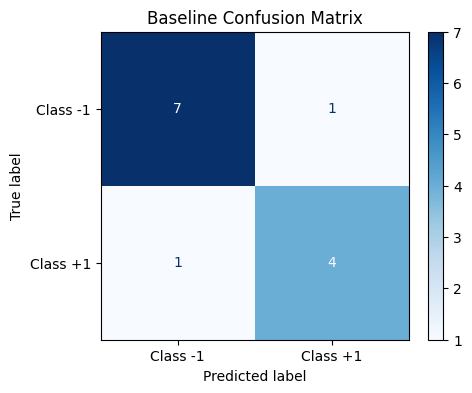

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_baseline,
    labels=[-1, 1],
    display_labels=["Class -1", "Class +1"],
    cmap="Blues",
    ax=ax
)

ax.set_title("Baseline Confusion Matrix")
plt.show()

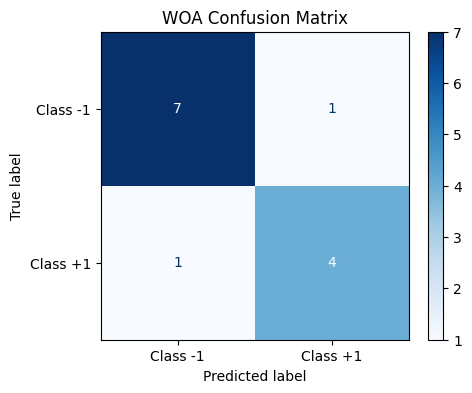

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_woa,
    labels=[-1, 1],
    display_labels=["Class -1", "Class +1"],
    cmap="Blues",
    ax=ax
)

ax.set_title("WOA Confusion Matrix")
plt.show()

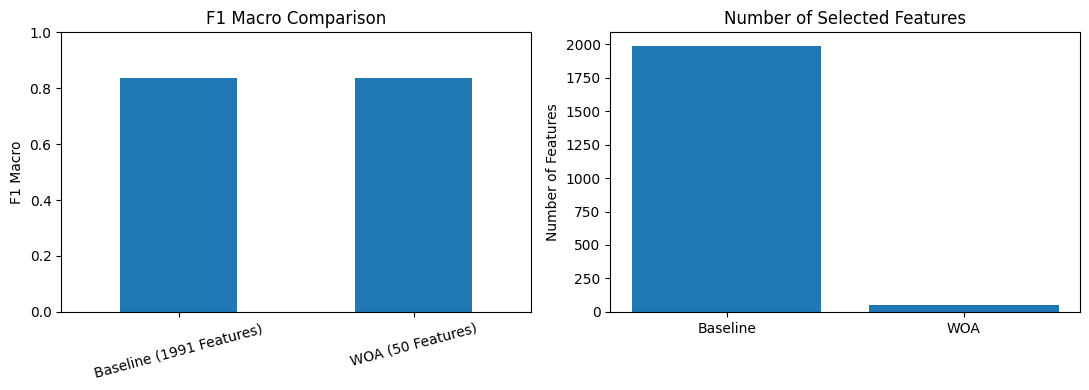

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Compare F1 Macro
comparison_df["F1 Macro"].plot(
    kind="bar",
    ax=axes[0],
    title="F1 Macro Comparison",
    ylim=(0, 1)
)

axes[0].set_ylabel("F1 Macro")
axes[0].tick_params(axis="x", rotation=15)

# Compare feature counts
axes[1].bar(
    ["Baseline", "WOA"],
    [X_train_baseline.shape[1], X_train_woa.shape[1]]
)

axes[1].set_title("Number of Selected Features")
axes[1].set_ylabel("Number of Features")

plt.tight_layout()
plt.show()

In [ ]:
original_feature_count = X_train_baseline.shape[1]
selected_feature_count = X_train_woa.shape[1]

reduction_percentage = (
    (original_feature_count - selected_feature_count)
    / original_feature_count
) * 100

print("Original features:", original_feature_count)
print("Selected features:", selected_feature_count)
print(f"Feature reduction: {reduction_percentage:.2f}%")

Original features: 1991
Selected features: 50
Feature reduction: 97.49%


In [ ]:
comparison_df.to_csv(
    RESULTS_PATH / "final_model_comparison.csv"
)

baseline_report = classification_report(
    y_test,
    y_pred_baseline,
    labels=[-1, 1],
    output_dict=True,
    zero_division=0
)

woa_report = classification_report(
    y_test,
    y_pred_woa,
    labels=[-1, 1],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(baseline_report).to_csv(
    RESULTS_PATH / "baseline_classification_report.csv"
)

pd.DataFrame(woa_report).to_csv(
    RESULTS_PATH / "woa_classification_report.csv"
)

print("Final evaluation results saved successfully.")

Final evaluation results saved successfully.
